# <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


##    <center>Extra 2: Vizualizarea datelor (cod complet)</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I, 2024-2025**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

### Cuprins
#### Recapitulare seminar 2
1. Citirea fisierelor 
2. Combinarea mai multor dataframe-uri
3. Lucrul cu dataframe-uri
#### Vizualizarea datelor: matplotlib, plotly

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/02-explorare-vizualizare/extra-02-vizualizarea-datelor.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/02-explorare-vizualizare
sys.path.insert(0, os.path.abspath("../.."))

# Recapitulare seminar 2

Citirea fișierelor în dataframe-uri se face utilizând metode specifice `pandas` pentru cele mai uzuale tipuri de fișiere:


Importuri necesare

In [2]:
# libraria pentru lucrul tabelar
import pandas as pd

# libraria pentru functii matematice
import numpy as np

# Vizualizare datelor

## Date numerice, date categoriale

> bar graph, box plot, scatter plot

In [3]:
import seaborn as sns # visualize
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import os
#%matplotinline

## Citirea datelor

Seturile de date se încarcă cu funcția `incarca` din pachetul cursului, la fel în Colab și pe calculatorul vostru. Nu trebuie descărcat nimic manual și nu trebuie modificată nicio cale:

```python
date = incarca("lab-set4")   # toate tabelele setului 4
df = date[0]                 # primul tabel (sau după nume: date["OnlineRetail"])
```

In [9]:
# Citirea datelor de laborator: nu trebuie modificată nicio cale.
# incarca("lab-set4") descarcă setul (doar prima dată) și întoarce tabelele lui;
# un tabel se alege după nume sau după poziție: date["OnlineRetail"] sau date[0].
from seed.date import incarca, lista_seturi
lista_seturi("lab")

In [17]:
# test ca pot citi datele 
for i in range(1,2):
    incarca('lab-set' +str(i))

Citire din ZIP pentru Set1
Citire CSV: DateLaborator/Kaggle/Set1/WA_Fn-UseC_-Telco-Customer-Churn.csv
Setul de date Set1 are 1 dataframe-uri.


## Exemplul 1. 
### Line plots

In [18]:
dataset = incarca("lab-set4")
dataset[0]

Citire din ZIP pentru Set4
Citire XLSX: DateLaborator/Kaggle/Set4/OnlineRetail.xlsx
Setul de date Set4 are 1 dataframe-uri.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


La citire am creat ceva generic, o listă de dataframe-uri, în caz că sunt prezente mai multe tabele. Pentru acest set de date avem un singur tabel și îl vom alege din listă. Explorăm coloanele și ne uităm la câteva înregistrări.

In [19]:
df1 = dataset[0]

In [20]:
df1.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [21]:
df1.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Ar fi interesant să vedem volumul lunar al vânzărilor. Pentru asta vom construi două noi coloane. Ulterior, când vom vorbi despre serii de timp, vom investiga moduri de agregare prin intermediul reeșantionării bazate pe index temporal. Acum însă vom face agregarea manual.

> ItemRevenue

> InvoiceMonth - asta va da un exemplu de formatare a datelor in Python

In [22]:
df1 = df1.assign( Revenue = df1['Quantity'] * df1['UnitPrice'])


Un mod eficace de a trece din format `datetime` in str:

In [23]:
from datetime import datetime
df1 = df1.assign(InvoiceMonth = df1['InvoiceDate'].apply(lambda x: str(100*x.year + x.month)[0:4] +
                                                        '-' +str(100*x.year + x.month)[4:] ))

In [24]:
df1.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


Să vedem volumul lunar de vânzări

In [25]:
df_sample = df1.groupby('InvoiceMonth', as_index = False)['Revenue'].agg('sum')
df_sample.head(5)

,InvoiceMonth,Revenue
0,2010-12,748957.020
1,2011-01,560000.260
2,2011-02,498062.650
3,2011-03,683267.080
4,2011-04,493207.121


Ca și cu toate celelalte, vizualizarea depinde de modulul folosit:

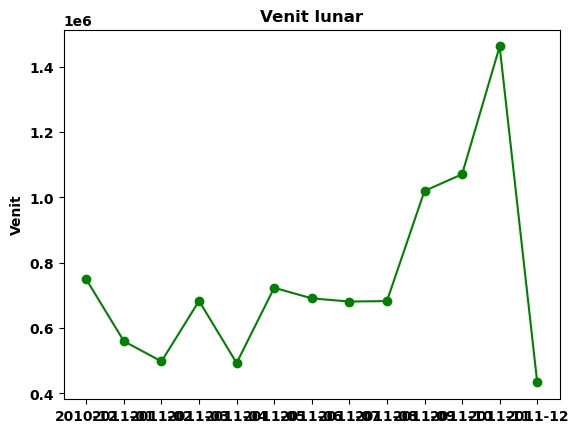

In [26]:

# un grafic cu punctele unite prin linii - 'line chart', lunile pe axa x, venitul pe y
plt.plot( df_sample.InvoiceMonth, 
         df_sample.Revenue, 
         color='green', marker='o', linestyle='solid')
# add a title
plt.title("Venit lunar")
# add a label to the y-axis
plt.ylabel("Venit")
plt.show()

După cum vedem, etichetele lunilor sunt suprascrise. Pentru a evita acest aspect putem roti etichetele, folosind o proprietate a plt.xticks - `rotation=45`:

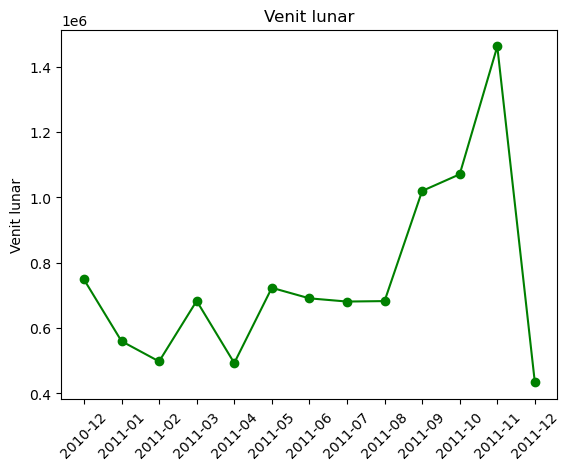

In [15]:
plt.plot(df_sample.InvoiceMonth, df_sample.Revenue, color='green', marker='o', linestyle='solid')
# add a title
plt.title("Venit lunar")
# add a label to the y-axis
plt.ylabel("Venit lunar")
plt.xticks(range(df_sample.shape[0]), df_sample.InvoiceMonth, rotation=45)
plt.show()

Acum sa vedem acelasi grafic cu seaborn


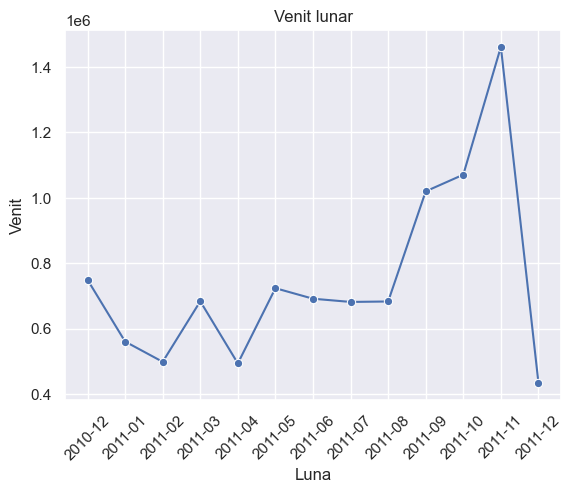

In [27]:
sns.set_theme() #Seteza parameterii estetici intr-un singur pas. Puteti explora cu stiluri

ax = sns.lineplot(x="InvoiceMonth", y="Revenue", data=df_sample, marker='o')
ax.set_title('Venit lunar')
ax.set_ylabel("Venit")
ax.set_xlabel("Luna")
ax.set_xticklabels(df_sample.InvoiceMonth, rotation = 45)
plt.show()

Același grafic cu plotly:

In [31]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x = df_sample.InvoiceMonth,
    y= df_sample.Revenue,
    mode = 'markers+lines'
    ))

fig.update_layout( 
    title = 'Venit Lunar',
    xaxis_title = 'Luna',
    yaxis_title = 'Venit (mil)')
fig.show()

fig.write_html('test.html')


# Exemplul 2. 

## Bar Charts

Un grafic de bare este o alegere bună atunci când doriți să arătați cum variază o anumită cantitate într-un un set de elemente discrete.

In [32]:
date_set1 = incarca("lab-set1")

Citire din ZIP pentru Set1
Citire CSV: DateLaborator/Kaggle/Set1/WA_Fn-UseC_-Telco-Customer-Churn.csv
Setul de date Set1 are 1 dataframe-uri.


In [33]:
df2=date_set1[0]

In [34]:
df2.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Să vedem distribuția clienților în funcție de pachetul de internet:

Text(0.5, 1.0, 'Număr clienți')

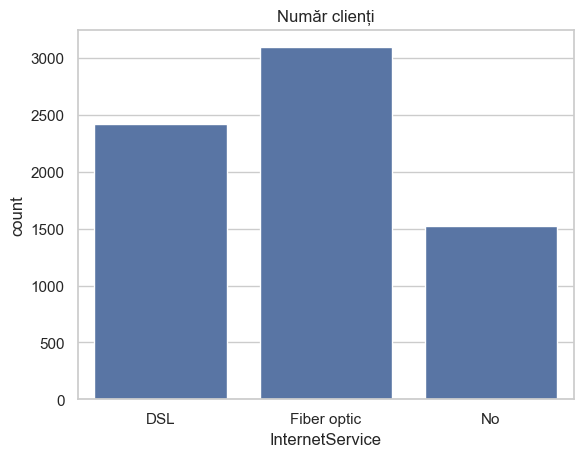

In [37]:

sns.set(style="whitegrid")
ax = sns.countplot(x="InternetService", data=df2)
ax.set_title('Număr clienți')

Dacă în loc de numărare(count) dorim să agregăm pe axa y o altă variabilă vom folosi

`seaborn.barplot`

De exemplu să vedem vârsta medie a celor care stau sau pleacă în funcție de sex:

In [38]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


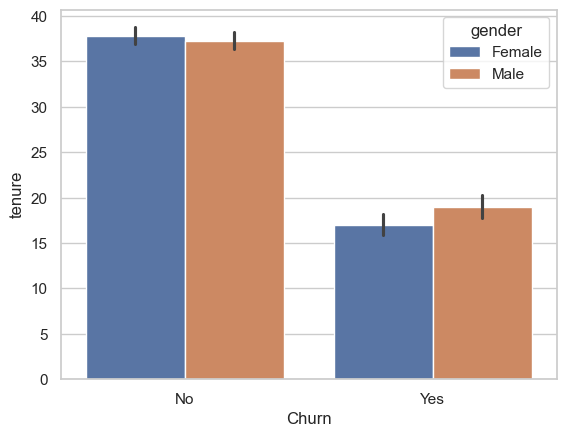

In [42]:
ax = sns.barplot( x= "Churn", y = "tenure", 
                 hue = "gender", data = df2)

Observăm în graficul anterior un parametru nou, `hue`, în funcție de care se pot face grupări. 

În cazul nostru puteam să calculăm și vechimea medie a celor care pleacă indiferent de sex. 

Distincția prin hue poate face mai relevantă informația. 

Acest parametru se poate folosi în mai toate graficele seaborn.

Mai jos încă un exemplu cu x si hue interschimbate.

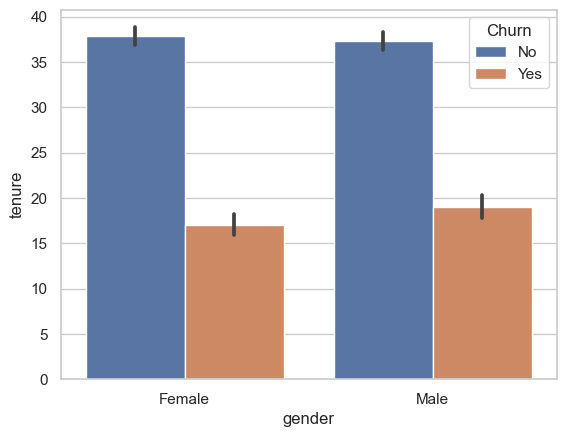

In [24]:
ax = sns.barplot( x= "gender", y = "tenure", hue = "Churn", data = df2)

Același tip de grafic cu plotly. Să notăm că agregările trebuie să le facem manual

In [25]:
import plotly.graph_objects as go

# nu putem evita scriere de cod, nu există un parametru echivalent cu hue
fig = go.Figure()
df_to_plot = df2.groupby(['gender','Churn'],as_index = False).agg( medie_abonament = ('tenure','mean'))

# pentru fiecare tip de churn adăugăm o bară
for churn in df_to_plot.Churn.unique():
    fig.add_trace(go.Bar(
        x=df_to_plot[df_to_plot.Churn == churn].gender,
        y=df_to_plot[df_to_plot.Churn == churn].medie_abonament,
        name= str(churn),
        #marker_color='indianred'
    ))

# Change the bar mode
fig.update_layout(barmode='group',
                 title = 'Plecări și media de durată a unui abonament după sex')
fig.show()

# Exemplul 3

## Histogram

Histogramele sunt o prezentare aproximativă a densității de distribuție a unei variabile continue.

In [43]:
date_echipa = incarca("lab-set2")


Citire din ZIP pentru Set2
Citire CSV: DateLaborator/Kaggle/Set2/employee_survey_data.csv
Citire CSV: DateLaborator/Kaggle/Set2/general_data.csv
Citire CSV: DateLaborator/Kaggle/Set2/in_time.csv
Citire CSV: DateLaborator/Kaggle/Set2/manager_survey_data.csv
Citire CSV: DateLaborator/Kaggle/Set2/out_time.csv
Setul de date Set2 are 5 dataframe-uri.


In [44]:
df3 = date_echipa[1]
df3.dtypes

Age                          int64
Attrition                   object
BusinessTravel              object
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeID                   int64
Gender                      object
JobLevel                     int64
JobRole                     object
MaritalStatus               object
MonthlyIncome                int64
NumCompaniesWorked         float64
Over18                      object
PercentSalaryHike            int64
StandardHours                int64
StockOptionLevel             int64
TotalWorkingYears          float64
TrainingTimesLastYear        int64
YearsAtCompany               int64
YearsSinceLastPromotion      int64
YearsWithCurrManager         int64
dtype: object

In [28]:
import plotly.graph_objects as go

import numpy as np

x0 = df3.MonthlyIncome


fig = go.Figure()
fig.add_trace(go.Histogram(x=x0))
#fig.add_trace(go.Histogram(x=x1))

# Overlay both histograms
fig.update_layout(barmode='overlay')
# Reduce opacity to see both histograms
#fig.update_traces(opacity=0.75)
fig.show()

Doua distributii in acelasi plot:

In [46]:
import plotly.graph_objects as go

import numpy as np

x0 = df3[df3.Gender == 'Male'].MonthlyIncome

x1 = df3[df3.Gender == 'Female'].MonthlyIncome

fig = go.Figure()
fig.add_trace(go.Histogram(x=x0, name ='Male'))
fig.add_trace(go.Histogram(x=x1, name = 'Female'))

# Overlay both histograms
fig.update_layout(barmode='overlay')
# Reduce opacity to see both histograms
fig.update_traces(opacity=0.75)
fig.update_layout(    title = 'Distribuția venitului - histogramă comparativă')
fig.show()

Grafice alăturate cu plotly

In [47]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# definim o matrice de imagini - numărul de linii și coloane decide așezarea în pagină
fig = make_subplots(rows=1, cols=2)

# imaginea din celula (1,1) - poate fi orice grafic, aici e una dintre histograme
fig.add_trace(go.Histogram(x=x0, name ='Male'),
              row=1, col=1)

# imaginea din celula (1,2)
fig.add_trace(go.Histogram(x=x1, name = 'Female'),
              row=1, col=2)

# adăugăm un titlu
fig.update_layout(    title = 'Distribuția venitului - histogramă comparativă')
fig.show()

## Exercitiul 3

1. Pe acelasi grafic reprezentati distributia venitului lunar (MonthlyIncome) pentru fiecare statut marital (MaritalStatus)


In [31]:
# codul vostru aici

2. In doua grafice alaturate reprezentati distributia distantei fata de casa (DistanceFromHome) pentru fiecare statut marital

In [32]:
# codul vostru aici

# Exemplul 4

## Pie charts

In [48]:
date_echipa = incarca("lab-set3")

Citire din ZIP pentru Set3
Citire CSV: DateLaborator/Kaggle/Set3/student-mat.csv
Citire CSV: DateLaborator/Kaggle/Set3/student-por.csv
Setul de date Set3 are 2 dataframe-uri.


In [49]:
df4 = date_echipa[0]

In [50]:
df4.dtypes

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Un alt mod de a prezenta agregări de categorii, la nivel de proporții, este pie chart: feliile de pizza/plăcintă.

Să vedem proporția copiilor pe tipurile de ocupație ale mamei precum și nota finală medie pe aceste grupuri.

Vom face un pie chart pentru proporții; vom colora specific grupurile și vom eticheta cu tipurile de ocupație.

In [62]:
df_sample = df4.groupby('Mjob')['absences'].agg(['mean','sum']).reset_index()\
    .sort_values(by = 'sum', ascending = False)


In [53]:
df_sample.dtypes

Mjob     object
mean    float64
sum       int64
dtype: object

Să facem un grafic și cu matplotlib:

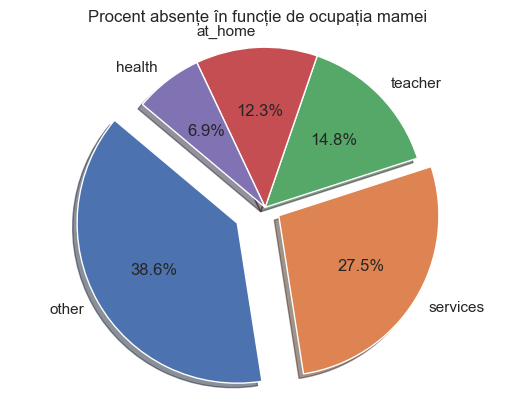

In [63]:
import matplotlib.pyplot as plt

# Data to plot
labels = df_sample['Mjob']
n = df_sample.shape[0]
sizes = df_sample['sum'].to_list()
#colors = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue','red']
# explode = (0.1, 0.2, 0, 0, 0)  # explode 1st slice
explode = [0.0] * n
explode[0] = 0.2
explode[1] = 0.1
# Plot
plt.pie(sizes, explode=tuple(explode), labels=labels, 
        #colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)
plt.title("Procent absențe în funcție de ocupația mamei")
plt.axis('equal')
plt.show()

# Exemplul 5

## Donut charts

Cu ajutorul acestui tip de grafic se pot reprezenta proportii de mai multe tipuri simultan.

In [64]:
date_echipa = incarca("lab-set5")

Citire din ZIP pentru Set5
Citire CSV: DateLaborator/Kaggle/Set5/credit_test.csv
Citire CSV: DateLaborator/Kaggle/Set5/credit_train.csv
Setul de date Set5 are 2 dataframe-uri.


In [65]:
date_echipa[0].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10353 entries, 0 to 10352
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Loan ID                       10000 non-null  object 
 1   Customer ID                   10000 non-null  object 
 2   Current Loan Amount           10000 non-null  float64
 3   Term                          10000 non-null  object 
 4   Credit Score                  8019 non-null   float64
 5   Annual Income                 8019 non-null   float64
 6   Years in current job          9573 non-null   object 
 7   Home Ownership                10000 non-null  object 
 8   Purpose                       10000 non-null  object 
 9   Monthly Debt                  10000 non-null  float64
 10  Years of Credit History       10000 non-null  float64
 11  Months since last delinquent  4694 non-null   float64
 12  Number of Open Accounts       10000 non-null  float64
 13  N

In [67]:
df5 = date_echipa[0]

Să încercăm să vedem proporția de proprietari (Home Ownership =  owners) care iau împrumut pentru a îmbunătăți casa (Purpose = home improvement)

In [68]:
df5.groupby('Home Ownership')['Loan ID'].agg('count').index

Index(['HaveMortgage', 'Home Mortgage', 'Own Home', 'Rent'], dtype='object', name='Home Ownership')

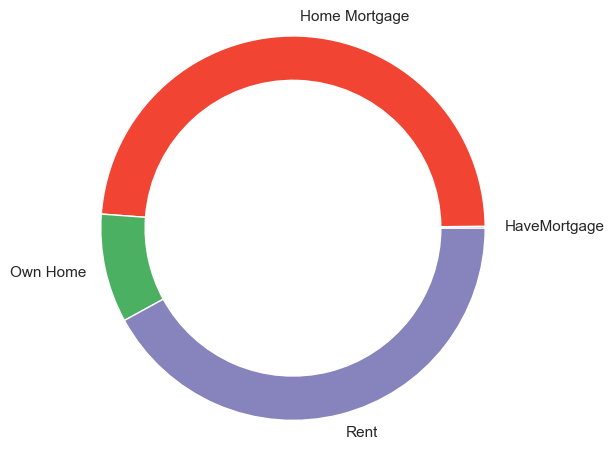

In [69]:
# Libraries
import matplotlib.pyplot as plt
 
# enumaram proprietarii
group_names = df5.groupby('Home Ownership')['Loan ID'].agg('count').index

# numaram proprietarii
group_size=df5.groupby('Home Ownership')['Loan ID'].agg('count').values

subgroup_names=df5.groupby(['Home Ownership','Purpose'])['Loan ID'].agg('count').index
subgroup_names=[s[1].replace("'","").replace("}","") for s in subgroup_names]
subgroup_size=df5.groupby(['Home Ownership','Purpose'])['Loan ID'].agg('count').values
 
# Creare culori
my_colors=[plt.cm.Blues, plt.cm.Reds, plt.cm.Greens, plt.cm.Purples, plt.cm.Oranges]
my_color_lenghts = date_echipa[0][['Home Ownership','Purpose']].drop_duplicates().groupby('Home Ownership')['Purpose'].count()

# Inel exterior
fig, ax = plt.subplots()
ax.axis('equal')
mypie, _ = ax.pie(group_size, radius=1.3, labels=group_names, colors=[c(0.6) for c in my_colors] )
plt.setp( mypie, width=0.3, edgecolor='white')
 
colors = []
for i in range(len(my_colors)):
    
    for j in range(subgroup_size[i]):
        colors.append(my_colors[i](0.6- j * 0.1))
        

plt.margins(0,0)
 
# show it
plt.show()

Același grafic cu plotly:

Agregăm datele la nivelul celor două dimensiuni - tipul de reședință actuală și scopul împrumutului.

In [70]:
df5_agg = df5.groupby(['Home Ownership','Purpose'], as_index = False).agg(
    LoanCount =('Loan ID','count'))
df5_agg

,Home Ownership,Purpose,LoanCount
0,HaveMortgage,Take a Trip,16
1,Home Mortgage,Business Loan,80
2,Home Mortgage,Buy House,27
3,Home Mortgage,Buy a Car,43
4,Home Mortgage,Debt Consolidation,3806
5,Home Mortgage,Educational Expenses,1
6,Home Mortgage,Home Improvements,458
7,Home Mortgage,Medical Bills,46
8,Home Mortgage,Other,113
9,Home Mortgage,major_purchase,17


In [45]:
import plotly.express as px

import numpy as np
df = df5_agg
fig = px.sunburst(df, path=['Home Ownership', 'Purpose'], values='LoanCount',
                  color='Purpose', #hover_data=['iso_alpha'],
                  color_continuous_scale='RdBlu',
                 # color_continuous_midpoint=np.average(df['Purpose'], weights=df['LoanCount'])
                 )
fig.show()

Parallel Category Graph

In [46]:
import plotly.graph_objects as go
import pandas as pd



# Create dimensions
ho_dim = go.parcats.Dimension(
    values=df5['Home Ownership'],
    categoryorder='category ascending', label="Home Ownership"
)

purpose_dim = go.parcats.Dimension(values=df5.Purpose, label="Purpose")

years_dim = go.parcats.Dimension(
    values=df5['Years in current job'], label="Years in current job"
)

# Create parcats trace
color = df5['Months since last delinquent']
colorscale = [[0, 'lightsteelblue'], [1, 'mediumseagreen']]

fig = go.Figure(data = [go.Parcats(dimensions=[ho_dim, purpose_dim, years_dim],
        line={'color': color, 'colorscale': colorscale},
        hoveron='color', hoverinfo='count+probability',
        labelfont={'size': 18, 'family': 'Times'},
        tickfont={'size': 16, 'family': 'Times'},
        arrangement='freeform')])

fig.show()

# Exercitiul 5

1. Donut chart cu distributia celor cu imprumut in functie de anii in care au istoric de credit (Years of Credit History)

Bonus: dispunerea radiala a etichetelor in graficul de mai sus cu doua inele.

# Exemplul 6

## Boxplot

Grafic care prezinta distributia unei variabile folosind precentile. Util pentru compararea unor distributii si a evolutiei in timp, sau pentru comparare alaturata a unor variabile continue asemanatoare

In [ ]:
date_echipa = incarca("lab-set6")
df6 = date_echipa[1]

citire pt  Set6
test.csv
train.csv
setul de date  Set6  are  2 dataframe-uri.


In [48]:
df6.YrSold.drop_duplicates()

0     2008
1     2007
3     2006
5     2009
16    2010
Name: YrSold, dtype: int64

Aș vrea să văd prețul caselor în boxplot. Apoi aș vrea să văd comparate boxploturi pe ani în același grafic ca să văd 
cum s-a modificat distribuția prețurilor în timp.

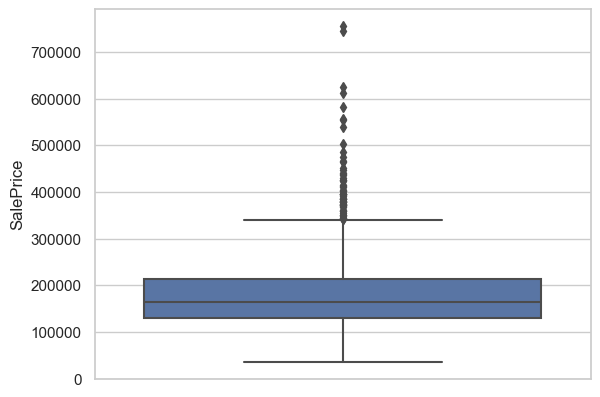

In [49]:
ax = sns.boxplot(y="SalePrice",data=df6)

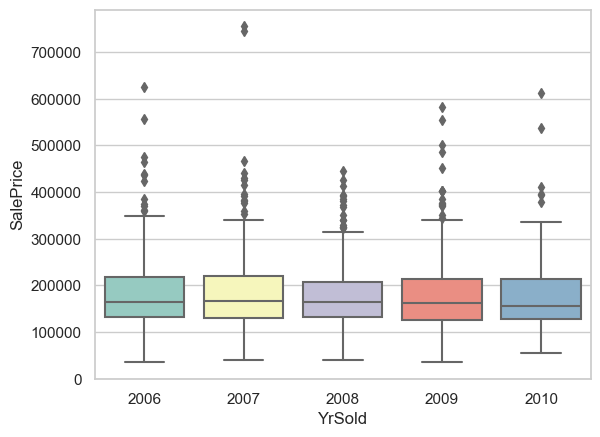

In [50]:
ax = sns.boxplot(x="YrSold", y="SalePrice", data=df6, palette="Set3")

Ames este un orășel universitar din statul Iowa. Vara sunt peste 30 Celsius cu umiditate, iar iarna ajunge și la -20 Celsius uneori pentru zile în șir. 

Să vedem cum este afectat prețul caselor de faptul că au sau nu au instalație mixtă de aer condiționat și de încălzire.

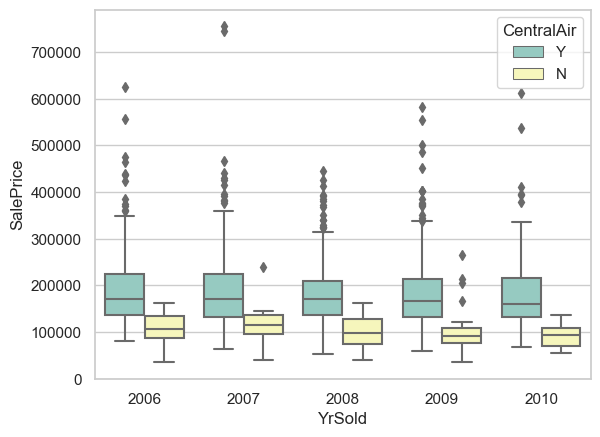

In [51]:
ax = sns.boxplot(x="YrSold", y="SalePrice", hue="CentralAir",data=date_echipa[1], palette="Set3")

# Exercitiul 6

1. Care sunt cartierele cu cele mai scumpe case? Exista acolo case fara instalatie de aer conditionat? 
Boxplot cu distributia preturilor (SalePrice) la case pretul de cel putin 500.000USD in functie de cartiere (Neighborhood) 

2.Care sunt cartierele cu cele mai ieftin case? Exista acolo case fara instalatie de aer conditionat? Are vreo relevanta in pret?
Boxplot cu distributia preturilor (SalePrice) la case pretul de cel putin 50.000USD in functie de cartiere (Neighborhood)

In [52]:
# codul vostru aici

# Exemplul 7 

## Scatterplot

In [ ]:
date_echipa = incarca("lab-set7")


citire pt  Set7
Test_Beneficiarydata-1542969243754.csv
Test_Inpatientdata-1542969243754.csv
Test_Outpatientdata-1542969243754.csv
Test-1542969243754.csv
Train_Beneficiarydata-1542865627584.csv
Train_Inpatientdata-1542865627584.csv
Train_Outpatientdata-1542865627584.csv
Train-1542865627584.csv
setul de date  Set7  are  8 dataframe-uri.


In [54]:
df7 = date_echipa[6]

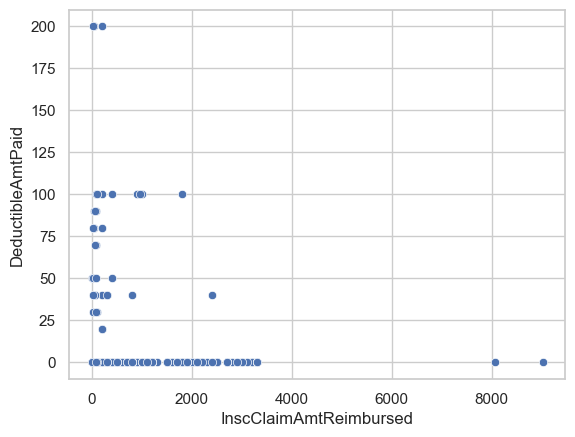

In [55]:
ax = sns.scatterplot(x="InscClaimAmtReimbursed", y="DeductibleAmtPaid", data=date_echipa[6].loc[0:1000])


In [56]:
df7[['InscClaimAmtReimbursed','DeductibleAmtPaid']].describe()

,InscClaimAmtReimbursed,DeductibleAmtPaid
count,517737.000000,517737.000000
mean,286.334799,2.779233
std,694.034343,15.785839
min,0.000000,0.000000
25%,40.000000,0.000000
50%,80.000000,0.000000
75%,200.000000,0.000000
max,102500.000000,897.000000


Vedem ca la despagubiri a 75 percentila e 200USD. Cati asiguratori sunt care au platit mai mult de 3000USD in despagubiri?

In [57]:
df7[df7.InscClaimAmtReimbursed>15000].shape

(21, 27)

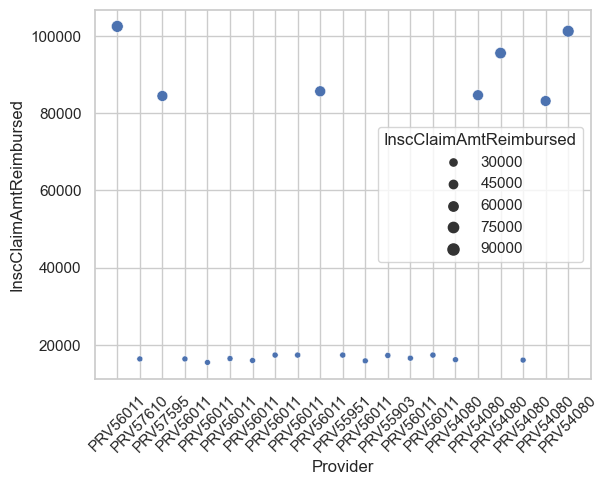

In [58]:
ax = sns.scatterplot(x="Provider", 
                     y="InscClaimAmtReimbursed", 
                     data=df7[df7.InscClaimAmtReimbursed>15000],
                     size = "InscClaimAmtReimbursed" )

ax.tick_params(axis='x', rotation=45)


In [59]:
# Bonus plots

In [60]:
## time series animation
## circular graphs https://mne.tools/stable/auto_examples/connectivity/plot_mne_inverse_label_connectivity.html
## word frequency

# Bonus plot - word count

Sunt multe librarii care fac asta. Vom folosi WordCloud care nu vine cu Anaconda si o vom instala ad-hoc

In [61]:
!pip install wordcloud

Scopul este să obținem o ilustarare grafică a asiguratorilor în funcție de numărul de cereri de despăgubire:

(-0.5, 399.5, 199.5, -0.5)

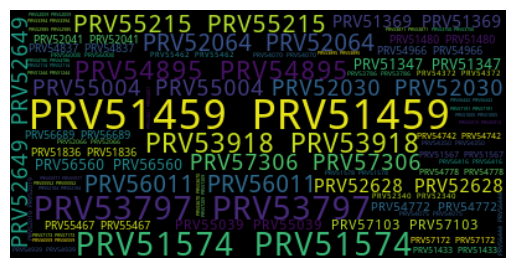

In [62]:
from wordcloud import WordCloud

# numaram cazurile pe asigurator
word_freq = df7.groupby('Provider')['ClaimID'].count()
text = " ".join([(k + " ")*v for k,v in word_freq.items()])

# Generare de word cloud image
wordcloud = WordCloud().generate(text)


# Display imagine generata:
# the matplotlib way:
import matplotlib.pyplot as plt
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")

